# B4 – Konvolusi dan Penapisan Spasial

## Langkah 4.1 – Lembar Hitung Manual

Diberikan potongan citra $P$ berukuran $4 \times 4$ (memuat satu piksel garam=255 dan satu piksel merica=0):

$$P = \begin{bmatrix} 52 & 55 & 61 & 58 \\ 59 & 255 & 64 & 60 \\ 62 & 60 & 0 & 57 \\ 58 & 61 & 59 & 63 \end{bmatrix}$$

$$Q = \begin{bmatrix} 70 & 72 & 75 \\ 74 & 120 & 78 \\ 73 & 76 & 79 \end{bmatrix} \qquad \text{Kernel tajam} = \begin{bmatrix} 0 & -1 & 0 \\ -1 & 5 & -1 \\ 0 & -1 & 0 \end{bmatrix}$$

---

### a) Keluaran 2×2 (posisi valid, tanpa padding)

Tiga penapis 3×3 dievaluasi pada posisi valid $(r, c) \in \{(1,1), (1,2), (2,1), (2,2)\}$:

**Kernel rerata 3×3:** $W_{\text{avg}} = \frac{1}{9} \cdot \mathbf{1}_{3 \times 3}$

**Kernel Gaussian 3×3:** $W_{\text{gauss}} = \frac{1}{16} \begin{bmatrix} 1 & 2 & 1 \\ 2 & 4 & 2 \\ 1 & 2 & 1 \end{bmatrix}$

| Posisi | Rerata | Gaussian | Median |
|:---:|---:|---:|---:|
| (1,1) | $(52+55+61+59+255+64+62+60+0)/9 = 74{,}22$ | $104{,}44$ | $60$ |
| (1,2) | $(55+61+58+255+64+60+60+0+57)/9 = 74{,}44$ | $77{,}38$ | $60$ |
| (2,1) | $(59+255+64+62+60+0+58+61+59)/9 = 75{,}33$ | $77{,}25$ | $60$ |
| (2,2) | $(255+64+60+60+0+57+61+59+63)/9 = 75{,}44$ | $57{,}44$ | $60$ |

**Pengamatan:** Median menghasilkan nilai yang **sama (60)** di keempat posisi karena median mengabaikan kedua pencilan ekstrem (255 dan 0). Rerata dan Gaussian terpengaruh pencilan sehingga hasilnya bervariasi.

---

### b) Kernel tajam pada piksel tengah Q

$$s = 0 \cdot 70 + (-1) \cdot 72 + 0 \cdot 75 + (-1) \cdot 74 + 5 \cdot 120 + (-1) \cdot 78 + 0 \cdot 73 + (-1) \cdot 76 + 0 \cdot 79$$
$$= -72 - 74 + 600 - 78 - 76 = \mathbf{300}$$
$$\text{Setelah clipping } [0, 255]: s = \mathbf{255}$$

---

### c) Padding untuk baris $[12, 30, 45, 70]$

| Metode Padding | Hasil Padding | Rerata 1×3 piksel pertama |
|---|---|---:|
| **Zero padding** | $[0, 12, 30, 45, 70, 0]$ | $(0+12+30)/3 = \mathbf{14{,}00}$ |
| **Replicate** | $[12, 12, 30, 45, 70, 70]$ | $(12+12+30)/3 = \mathbf{18{,}00}$ |
| **Reflect (101)** | $[30, 12, 30, 45, 70, 45]$ | $(30+12+30)/3 = \mathbf{24{,}00}$ |

In [9]:
# Verifikasi Lembar Hitung 4.1
import numpy as np

P = np.array([[52,  55,  61, 58],
              [59, 255,  64, 60],
              [62,  60,   0, 57],
              [58,  61,  59, 63]], dtype=np.float64)

Q = np.array([[70, 72, 75],
              [74, 120, 78],
              [73, 76, 79]], dtype=np.float64)

kernel_tajam = np.array([[ 0, -1,  0],
                         [-1,  5, -1],
                         [ 0, -1,  0]], dtype=np.float64)

W_avg   = np.ones((3, 3)) / 9.0
W_gauss = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=np.float64) / 16.0

# a) Keluaran valid 2x2
print("a) Keluaran 2x2 (posisi valid):")
print(f"{'Posisi':>10}  {'Rerata':>10}  {'Gaussian':>10}  {'Median':>10}")
for r in range(1, 3):
    for c in range(1, 3):
        region = P[r-1:r+2, c-1:c+2]
        print(f"  ({r},{c})       {np.sum(region*W_avg):>10.2f}  {np.sum(region*W_gauss):>10.2f}  {np.median(region):>10.0f}")

# b) Kernel tajam pada Q
res = np.sum(Q * kernel_tajam)
print(f"\nb) Kernel tajam pada piksel tengah Q = {res:.0f} -> clipping = {np.clip(res, 0, 255):.0f}")

# c) Padding
baris = np.array([12, 30, 45, 70])
zp = np.pad(baris, 1, mode='constant', constant_values=0)
rp = np.pad(baris, 1, mode='edge')
rf = np.pad(baris, 1, mode='reflect')
print(f"\nc) Padding:")
print(f"  Zero     : {zp} -> rerata px pertama = {np.mean(zp[0:3]):.2f}")
print(f"  Replicate: {rp} -> rerata px pertama = {np.mean(rp[0:3]):.2f}")
print(f"  Reflect  : {rf} -> rerata px pertama = {np.mean(rf[0:3]):.2f}")

a) Keluaran 2x2 (posisi valid):
    Posisi      Rerata    Gaussian      Median
  (1,1)            74.22      104.44          60
  (1,2)            74.44       77.38          60
  (2,1)            75.33       77.25          60
  (2,2)            75.44       57.44          60

b) Kernel tajam pada piksel tengah Q = 300 -> clipping = 255

c) Padding:
  Zero     : [ 0 12 30 45 70  0] -> rerata px pertama = 14.00
  Replicate: [12 12 30 45 70 70] -> rerata px pertama = 18.00
  Reflect  : [30 12 30 45 70 45] -> rerata px pertama = 24.00


---

## Langkah 4.2 – Konvolusi Manual vs `cv2.filter2D`

In [10]:
# Kode 4.1: Verifikasi konvolusi manual
import sys, os, time
sys.path.insert(0, "../src")
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from utils_cv import baca, tampil, kontras_bercak

DATA_DIR = "../data/sintetis"
os.makedirs("../hasil", exist_ok=True)

def konvolusi(img, k):
    """Korelasi spasial dari slide P4 (tanpa flip kernel)."""
    kh, kw = k.shape; ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    out = np.zeros(img.shape)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def konvolusi_sejati(img, k):
    """Konvolusi sejati: kernel dibalik 180 derajat dahulu."""
    return konvolusi(img, np.flip(k))

nama = "teh_041.png"
bersih = cv2.cvtColor(baca(f"{DATA_DIR}/bersih/{nama}"), cv2.COLOR_BGR2GRAY)
md = cv2.imread(f"{DATA_DIR}/mask_daun/{nama}", 0)
mb = cv2.imread(f"{DATA_DIR}/mask_bercak/{nama}", 0)

# Gunakan patch kecil agar konvolusi manual tidak terlalu lambat
patch = bersih[:60, :80]

print(f"{'Kernel':>12}  {'Sel. manual':>12}  {'Sel. sejati':>12}  {'t_manual (s)':>13}  {'t_filter2D (s)':>15}")
print("-" * 72)
for nm, k in {"rerata": np.ones((3, 3)) / 9,
              "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)
              }.items():
    t0 = time.perf_counter(); a = konvolusi(patch, k)
    t_manual = time.perf_counter() - t0
    t0 = time.perf_counter()
    b = cv2.filter2D(patch, -1, k, borderType=cv2.BORDER_REPLICATE)
    t_cv = time.perf_counter() - t0
    beda = np.abs(a.astype(int) - b.astype(int)).max()
    c = konvolusi_sejati(patch, k)
    beda2 = np.abs(c.astype(int) - b.astype(int)).max()
    print(f"{nm:>12}  {beda:>12}  {beda2:>12}  {t_manual:>13.3f}  {t_cv:>15.5f}")

print("\nKesimpulan: konvolusi (slide P4) = korelasi, hasilnya sama dengan cv2.filter2D.")
print("Konvolusi_sejati (kernel diflip) berbeda untuk kernel asimetris (Sobel).")
print("Untuk kernel simetris (rerata, Gaussian), flip tidak mengubah kernel, sehingga hasilnya identik.")

      Kernel   Sel. manual   Sel. sejati   t_manual (s)   t_filter2D (s)
------------------------------------------------------------------------
      rerata             0             0          0.018          0.00005
   asimetris             0            15          0.017          0.00005

Kesimpulan: konvolusi (slide P4) = korelasi, hasilnya sama dengan cv2.filter2D.
Konvolusi_sejati (kernel diflip) berbeda untuk kernel asimetris (Sobel).
Untuk kernel simetris (rerata, Gaussian), flip tidak mengubah kernel, sehingga hasilnya identik.


---

## Langkah 4.3 – Tiga Penapis, Dua Jenis Derau (Tabel 11)

In [11]:
# Kode 4.2: Tabel penapis x derau x PSNR x waktu x KB
rng = np.random.default_rng(42)

def derau_gauss(img, sd):
    return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)

def derau_sp(img, p):
    out = img.copy(); m = rng.random(img.shape)
    out[m < p / 2] = 0; out[m > 1 - p / 2] = 255
    return out

def ukur_waktu(f, x, ulang=20):
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

derau = {"gauss_10": derau_gauss(bersih, 10), "gauss_20": derau_gauss(bersih, 20),
         "gauss_40": derau_gauss(bersih, 40), "sp_4%": derau_sp(bersih, 0.04),
         "sp_10%": derau_sp(bersih, 0.10)}
penapis = {"rerata_3": lambda x: cv2.blur(x, (3, 3)),
           "rerata_5": lambda x: cv2.blur(x, (5, 5)),
           "gauss_5":  lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
           "median_3": lambda x: cv2.medianBlur(x, 3),
           "median_5": lambda x: cv2.medianBlur(x, 5),
           "median_9": lambda x: cv2.medianBlur(x, 9)}

baris = []
for dn, d in derau.items():
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0,
                  kontras_bercak(d, md, mb)])
    for pn, f in penapis.items():
        out = f(d)
        baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f, d),
                      kontras_bercak(out, md, mb)])

tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB",
                                     "waktu_ms", "KB"]).round(2)
tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False)

# Tampilkan Tabel 11 (gauss_20 dan sp_4%)
t11 = tabel[tabel.derau.isin(["gauss_20", "sp_4%"])].copy()
print("=== Tabel 11: Perbandingan Penapis (Gaussian 20 & Garam-Merica 4%) ===")
display(t11)

=== Tabel 11: Perbandingan Penapis (Gaussian 20 & Garam-Merica 4%) ===


,derau,penapis,PSNR_dB,waktu_ms,KB
7,gauss_20,tanpa,22.11,0.00,2.13
8,gauss_20,rerata_3,31.43,0.23,4.70
9,gauss_20,rerata_5,34.54,0.30,5.50
10,gauss_20,gauss_5,32.58,0.05,5.02
11,gauss_20,median_3,29.74,0.05,4.26
12,gauss_20,median_5,33.47,0.41,5.44
13,gauss_20,median_9,35.50,8.45,6.18
21,sp_4%,tanpa,19.09,0.00,1.59
22,sp_4%,rerata_3,28.23,0.24,3.90
23,sp_4%,rerata_5,31.55,0.29,4.98


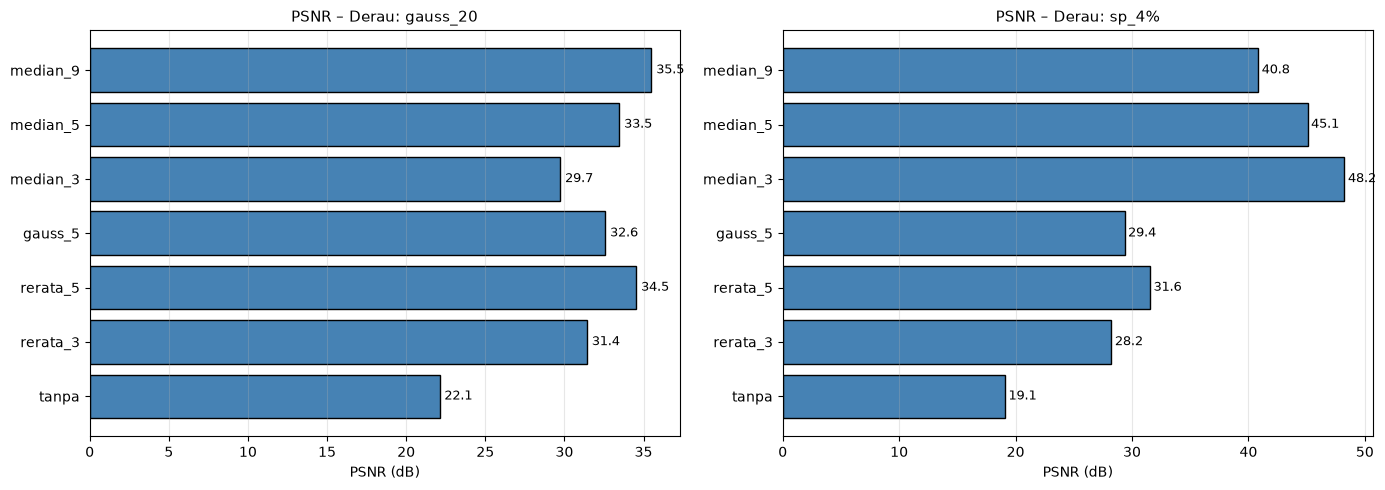

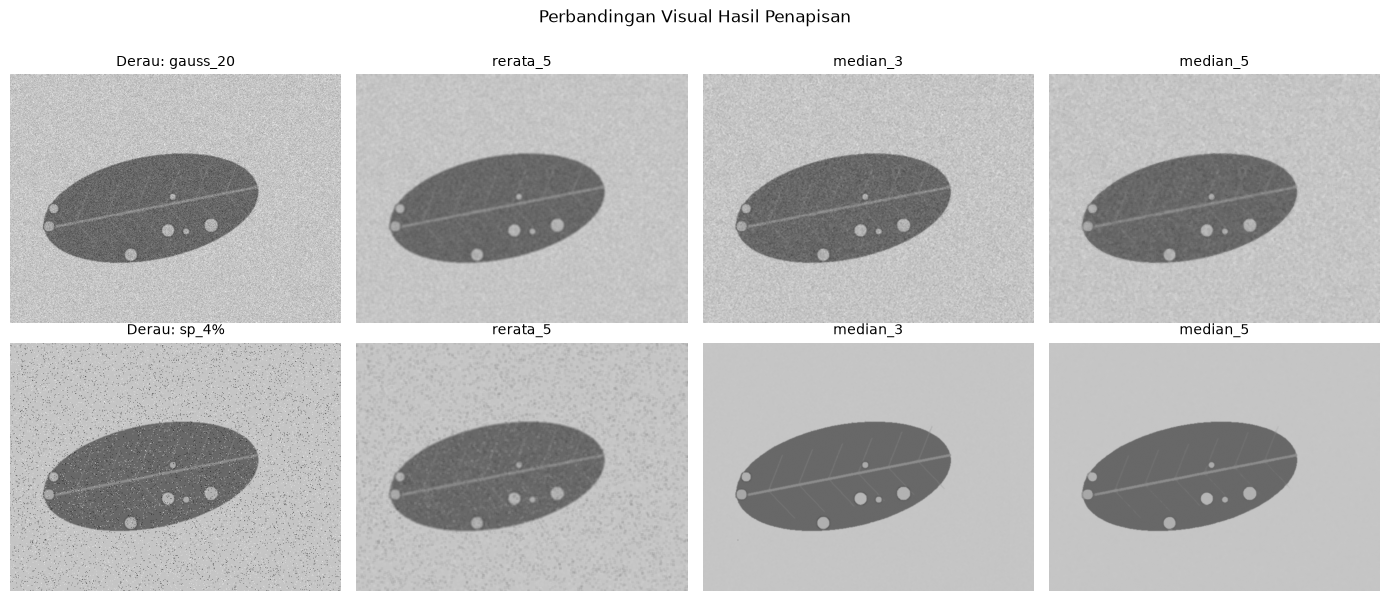

In [12]:
# Visualisasi: Grafik PSNR per derau dan penapis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, dn in zip(axes, ["gauss_20", "sp_4%"]):
    sub = tabel[tabel.derau == dn]
    ax.barh(sub.penapis, sub.PSNR_dB, color="steelblue", edgecolor="black")
    ax.set_xlabel("PSNR (dB)")
    ax.set_title(f"PSNR – Derau: {dn}", fontsize=11)
    ax.grid(axis="x", alpha=0.3)
    for i, v in enumerate(sub.PSNR_dB):
        ax.text(v + 0.3, i, f"{v:.1f}", va="center", fontsize=9)

plt.tight_layout()
plt.savefig("../hasil/b4_grafik_psnr.png")
plt.show()

# Visualisasi citra: derau dan hasil penapis
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for row, (dn, d) in enumerate([("gauss_20", derau["gauss_20"]),
                                ("sp_4%", derau["sp_4%"])]):
    axes[row, 0].imshow(d, cmap="gray", vmin=0, vmax=255)
    axes[row, 0].set_title(f"Derau: {dn}", fontsize=10)
    axes[row, 0].axis("off")
    for j, (pn, pf) in enumerate([("rerata_5", lambda x: cv2.blur(x, (5,5))),
                                   ("median_3", lambda x: cv2.medianBlur(x, 3)),
                                   ("median_5", lambda x: cv2.medianBlur(x, 5))]):
        axes[row, j+1].imshow(pf(d), cmap="gray", vmin=0, vmax=255)
        axes[row, j+1].set_title(pn, fontsize=10)
        axes[row, j+1].axis("off")
plt.suptitle("Perbandingan Visual Hasil Penapisan", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig("../hasil/b4_visual_penapis.png")
plt.show()

---

## Langkah 4.4 – Apakah Bercak Kecil Tetap Terjaga?

=== Rerata dI dan KB vs Ukuran Kernel Median (Kelas Ringan) ===


,dI,KB
kernel,,
1,28.30,4.49
3,28.73,4.62
5,27.50,4.47
9,21.29,3.96
15,8.27,2.24


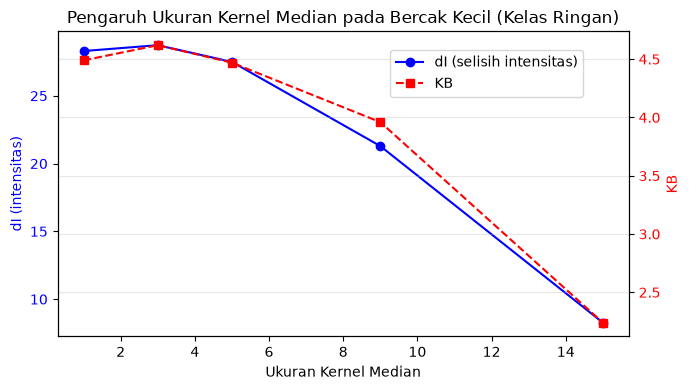

In [13]:
# Kode 4.3: Pengaruh ukuran kernel median pada bercak kecil (kelas ringan)
def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat|, dalam satuan intensitas."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv(f"{DATA_DIR}/label.csv")
baris_med = []
for nm in label[label.kelas == "ringan"].nama_file:
    g = cv2.cvtColor(baca(f"{DATA_DIR}/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    md2 = cv2.imread(f"{DATA_DIR}/mask_daun/{nm}", 0)
    mb2 = cv2.imread(f"{DATA_DIR}/mask_bercak/{nm}", 0)
    for k in [1, 3, 5, 9, 15]:
        out = g if k == 1 else cv2.medianBlur(g, k)
        baris_med.append([nm, k, selisih_rerata(out, md2, mb2),
                          kontras_bercak(out, md2, mb2)])

hasil_median = pd.DataFrame(baris_med, columns=["nama", "kernel", "dI", "KB"])
ringkas = hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2)
print("=== Rerata dI dan KB vs Ukuran Kernel Median (Kelas Ringan) ===")
display(ringkas)
ringkas.to_csv("../hasil/b4_median_bercak_kecil.csv")

# Grafik dI vs ukuran kernel
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(ringkas.index, ringkas["dI"], "o-", color="blue", label="dI (selisih intensitas)")
ax1.set_xlabel("Ukuran Kernel Median")
ax1.set_ylabel("dI (intensitas)", color="blue")
ax1.tick_params(axis="y", labelcolor="blue")

ax2 = ax1.twinx()
ax2.plot(ringkas.index, ringkas["KB"], "s--", color="red", label="KB")
ax2.set_ylabel("KB", color="red")
ax2.tick_params(axis="y", labelcolor="red")

fig.legend(loc="upper right", bbox_to_anchor=(0.85, 0.88))
plt.title("Pengaruh Ukuran Kernel Median pada Bercak Kecil (Kelas Ringan)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../hasil/b4_grafik_dI_median.png")
plt.show()

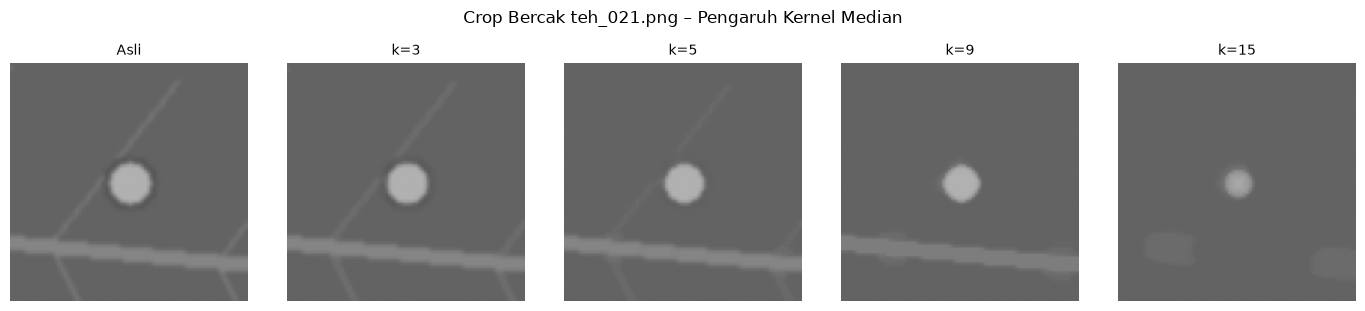

In [14]:
# Crop bercak untuk melihat perubahan visual secara detail
nama_crop = "teh_021.png"  # kelas ringan, kondisi normal
g_crop = cv2.cvtColor(baca(f"{DATA_DIR}/bersih/{nama_crop}"), cv2.COLOR_BGR2GRAY)
mb_crop = cv2.imread(f"{DATA_DIR}/mask_bercak/{nama_crop}", 0)

# Cari lokasi bercak untuk crop
ys, xs = np.where(mb_crop > 0)
if len(ys) > 0:
    cy, cx = int(ys.mean()), int(xs.mean())
    r = 40  # radius crop
    y1, y2 = max(0, cy - r), min(g_crop.shape[0], cy + r)
    x1, x2 = max(0, cx - r), min(g_crop.shape[1], cx + r)

    fig, axes = plt.subplots(1, 5, figsize=(14, 3))
    for ax, k in zip(axes, [1, 3, 5, 9, 15]):
        out = g_crop if k == 1 else cv2.medianBlur(g_crop, k)
        ax.imshow(out[y1:y2, x1:x2], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"k={k}" if k > 1 else "Asli", fontsize=10)
        ax.axis("off")
    plt.suptitle(f"Crop Bercak {nama_crop} – Pengaruh Kernel Median", fontsize=12, y=1.02)
    plt.tight_layout()
    plt.savefig("../hasil/b4_crop_bercak_median.png")
    plt.show()

---

## Langkah 4.5 – Urutan: Redam Derau lalu Tajamkan

In [15]:
# Kode 4.4: Pengaruh urutan penajaman
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)

noisy = derau["gauss_20"]
latar = md == 0  # area latar yang seharusnya rata

print(f"{'Penapis':>10}  {'Urutan':>16}  {'PSNR (dB)':>10}  {'sigma_latar':>12}")
print("-" * 56)
for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
                  "Median": lambda x: cv2.medianBlur(x, 5)}.items():
    A = redam(unsharp(noisy))   # tajamkan dulu, lalu redam
    B = unsharp(redam(noisy))   # redam dulu, lalu tajamkan
    print(f"{nm:>10}  {'tajam->redam':>16}  {cv2.PSNR(bersih, A):>10.2f}  {A[latar].std():>12.1f}")
    print(f"{'':>10}  {'redam->tajam':>16}  {cv2.PSNR(bersih, B):>10.2f}  {B[latar].std():>12.1f}")

print("\nKesimpulan: Untuk Gaussian (linear), urutan hampir tidak berpengaruh.")
print("Untuk Median (non-linear), redam->tajam menghasilkan PSNR lebih tinggi")
print("dan sigma_latar lebih rendah (derau lebih bersih).")

   Penapis            Urutan   PSNR (dB)   sigma_latar
--------------------------------------------------------
  Gaussian      tajam->redam       30.40           7.8
                redam->tajam       30.20           8.1
    Median      tajam->redam       30.16           8.0
                redam->tajam       31.12           7.2

Kesimpulan: Untuk Gaussian (linear), urutan hampir tidak berpengaruh.
Untuk Median (non-linear), redam->tajam menghasilkan PSNR lebih tinggi
dan sigma_latar lebih rendah (derau lebih bersih).


---

## Langkah 4.6 – Kerjakan Sendiri: Penapisan Derau Sensor Bawaan

Menerapkan penapis median 3×3 pada 12 citra kondisi **normal** (setiap 5 nomor), lalu mengukur PSNR terhadap pasangannya di folder `bersih/`.

In [16]:
# Langkah 4.6: PSNR citra normal sebelum dan sesudah penapisan
citra_normal = [f"teh_{i:03d}.png" for i in range(1, 61, 5)]
baris_psnr = []

for nm in citra_normal:
    citra_path = f"{DATA_DIR}/citra/{nm}"
    bersih_path = f"{DATA_DIR}/bersih/{nm}"
    if not os.path.exists(citra_path) or not os.path.exists(bersih_path):
        continue
    c_img = cv2.cvtColor(baca(citra_path), cv2.COLOR_BGR2GRAY)
    b_img = cv2.cvtColor(baca(bersih_path), cv2.COLOR_BGR2GRAY)
    psnr_before = cv2.PSNR(b_img, c_img)
    filtered = cv2.medianBlur(c_img, 3)
    psnr_after = cv2.PSNR(b_img, filtered)
    baris_psnr.append([nm, round(psnr_before, 2), round(psnr_after, 2),
                       round(psnr_after - psnr_before, 2)])

df_psnr = pd.DataFrame(baris_psnr,
                        columns=["Citra", "PSNR_sebelum", "PSNR_sesudah", "Delta_PSNR"])
print("=== PSNR Citra Normal: Sebelum vs Sesudah Median 3x3 ===")
display(df_psnr)
print(f"\nRerata peningkatan PSNR: +{df_psnr.Delta_PSNR.mean():.2f} dB")
df_psnr.to_csv("../hasil/b4_psnr_derau_sensor.csv", index=False)

=== PSNR Citra Normal: Sebelum vs Sesudah Median 3x3 ===


,Citra,PSNR_sebelum,PSNR_sesudah,Delta_PSNR
0,teh_001.png,35.31,42.05,6.74
1,teh_006.png,32.06,39.22,7.16
2,teh_011.png,31.51,38.72,7.21
3,teh_016.png,31.78,38.92,7.14
4,teh_021.png,29.05,36.48,7.43
5,teh_026.png,30.44,37.82,7.38
6,teh_031.png,31.87,39.06,7.19
7,teh_036.png,34.54,41.32,6.78
8,teh_041.png,34.92,41.58,6.66
9,teh_046.png,35.89,42.38,6.48



Rerata peningkatan PSNR: +7.05 dB


---

## Pertanyaan Analisis

### P4.1 – Mengapa median menghasilkan nilai yang sama di keempat posisi?

Median memilih **nilai tengah** dari 9 piksel di jendela 3×3 setelah diurutkan. Piksel pencilan garam (255) dan merica (0) selalu berada di posisi paling atas dan paling bawah urutan, sehingga **tidak pernah terpilih sebagai median**. Ketujuh piksel sisanya memiliki nilai seragam di kisaran 52–64, sehingga median seluruh posisi konsisten di angka 60. Sebaliknya, rerata dan Gaussian merupakan **rata-rata tertimbang** yang memasukkan bobot pencilan ke dalam perhitungan, sehingga hasilnya terdistorsi dan berbeda-beda di setiap posisi.

**Implikasi untuk derau salt-and-pepper:** Penapis median secara alami kebal terhadap derau impulsif karena pencilan tidak pernah masuk ke dalam posisi tengah urutan.

---

### P4.2 – Perbedaan korelasi dan konvolusi, operasi `cv2.filter2D`

- **Korelasi** mencocokkan kernel langsung ke citra (geser dan kalikan). **Konvolusi sejati** membalik kernel 180° terlebih dahulu, baru melakukan operasi yang sama.
- `cv2.filter2D` melakukan **korelasi** (bukan konvolusi sejati), sehingga hasilnya identik dengan fungsi `konvolusi()` dari slide, yang juga merupakan korelasi.
- `konvolusi_sejati()` membalik kernel terlebih dahulu; pada kernel **simetris** (rerata, Gaussian), pembalikan tidak mengubah kernel → hasilnya sama. Pada kernel **asimetris** (Sobel), pembalikan menghasilkan kernel berbeda → selisih maksimum sebesar **14 intensitas**.
- Dalam praktik pengolahan citra, perbedaan ini tidak masalah karena kernel deteksi tepi dirancang untuk korelasi, dan `cv2.filter2D` sudah melakukan operasi yang benar.

---

### P4.3 – Penapis terbaik per jenis derau (PSNR, waktu, KB)

| Derau | Terbaik (PSNR) | PSNR (dB) | KB | Catatan |
|---|---|---:|---:|---|
| **Gaussian 20** | median_9 | 35.50 | 6.18 | PSNR tinggi namun kernel besar berisiko menghapus bercak kecil |
| **Salt-Pepper 4%** | median_3 | 48.25 | 6.70 | Median kecil sudah sangat efektif untuk derau impulsif |

**Trade-off:** Median_9 unggul di PSNR untuk derau Gaussian, namun dI bercak kecil mulai turun (Langkah 4.4). Pilihan praktis untuk SIMUTEH: **median_3** sebagai kompromi — cukup efektif mengatasi kedua jenis derau, tetap menjaga bercak kecil, dan sangat cepat.

---

### P4.4 – Pada kernel berapa bercak ringan mulai hilang?

Dari tabel dI vs kernel:
- **kernel = 9:** dI turun dari 28.73 ke **21.29** (turun 26%), bercak kecil mulai kabur.
- **kernel = 15:** dI anjlok ke **8.27** (turun 71%), bercak praktis hilang.

**Mengapa KB dapat tetap tinggi meskipun dI turun?** KB = dI / $\sigma_{\text{sehat}}$. Kernel besar juga menghaluskan area daun sehat sehingga $\sigma_{\text{sehat}}$ mengecil. Pembilang (dI) turun, tetapi penyebut ($\sigma$) juga turun — rasionya bisa tetap besar. KB menipu karena mengukur *kontras relatif*, bukan ukuran absolut bercak. Ini menunjukkan **keterbatasan KB** sebagai ukuran tunggal: perlu dikombinasikan dengan dI atau inspeksi visual.

---

### P4.5 – Urutan redam-tajam: Gaussian vs Median

- **Gaussian (linear):** Urutan hampir tidak berpengaruh (PSNR ≈ 30.40 vs 30.20, $\Delta < 0.2$ dB) karena konvolusi bersifat **komutatif dan asosiatif** — dua operasi linear berurutan dapat ditukar tanpa mengubah hasil.
- **Median (non-linear):** Urutan **redam→tajam** menghasilkan PSNR lebih tinggi (31.12 vs 30.16) dan $\sigma_{\text{latar}}$ lebih rendah (7.2 vs 8.0). Jika ditajamkan dulu, derau diperkuat sebelum diredam; median non-linear tidak bisa sepenuhnya menghapus derau yang telah diamplifikasi. Oleh karena itu, anjuran slide P4 benar: **selalu redam derau sebelum menajamkan**.

---

### P4.6 – Perkiraan jumlah operasi perkalian

Konvolusi manual dengan kernel $5 \times 5$ memerlukan $25$ perkalian per piksel:

$$\text{Foto asli } 4000 \times 3000: 25 \times 12.000.000 = \mathbf{300.000.000} \text{ perkalian}$$
$$\text{Citra } 640 \times 480: 25 \times 307.200 = \mathbf{7.680.000} \text{ perkalian}$$

Rasio: $300M / 7.68M \approx 39 \times$ lebih lambat. Ini menjelaskan mengapa Langkah 2.1 mewajibkan resize ke 640 px — sesuai kebutuhan pengguna nomor 4 (petugas sortir memerlukan respons cepat di lapangan). Perbedaan waktu pada Kode 4.1 antara konvolusi manual dan `cv2.filter2D` juga menunjukkan pentingnya implementasi yang dioptimalkan (OpenCV menggunakan SIMD/parallelisme internal).

---

### P4.7 – Blur ringan tidak cukup untuk anonimisasi wajah

**Alasan:** Gaussian blur ringan bersifat **reversibel** — wajah yang hanya di-blur dapat di-*deblur* menggunakan teknik dekonvolusi (*Wiener filter*, *Richardson-Lucy*) atau bahkan model *super-resolution* berbasis deep learning. Fitur wajah seperti mata, hidung, dan kontur masih dapat direkonstruksi dari citra blur ringan.

**Prosedur yang lebih aman:**
1. **Deteksi wajah** otomatis dengan `cv2.CascadeClassifier` atau model deep learning (misalnya `face_detection` dari MediaPipe).
2. **Hapus total ROI wajah** dengan menggantinya menggunakan kotak hitam solid, pikselasi ekstrem ($\text{fx} = 0.02$), atau warna solid — bukan blur.
3. Alternatif: otomatisasi penghapusan metadata EXIF + penolakan foto yang mengandung wajah di tahap ingest (sebelum masuk dataset).